# BreastMNIST analysis using PyTorch

### **Step 1: Package Import**

In [129]:
from importlib.metadata import version
from torchvision import transforms
from torch.utils.data import DataLoader
import os
import copy
import numpy
import pandas
import torch
from torch import nn
import medmnist
import matplotlib.pyplot as pyplot
import sklearn.metrics

packages = ["torch", "torchvision", "medmnist", "numpy", "pandas", "scikit-learn", "matplotlib", "ipykernel"]

for package in packages:
    print(package + "==" + version(package))

torch==2.15.0
torchvision==0.29.2
medmnist==3.0.2
numpy==2.5.4
pandas==3.1.1
scikit-learn==1.9.1
matplotlib==3.11.2
ipykernel==7.4.0


### **Step 2: Data Download**

Based on the official MedMNIST documentation:

- The file ./data/breastmnist.npz holds six arrays: one for images 
and one for labels for each of the training, validation and test splits.

- Images are grayscale and 28 by 28 pixels, so the training images should 
have the shape (546, 28, 28) and the training labels the shape (546, 1).

- Each label is a single number, 0 or 1, because this is a two-class task.

- The standard split is already provided: 546 training, 78 validation and
156 test images (780 in total),  by the MedMNIST authors, so that everyone 
uses the same test images and results can be compared. The data is for 
learning and research only, not for clinical use.

In [130]:
import os
from medmnist import BreastMNIST

os.makedirs("data", exist_ok=True)

train_data = BreastMNIST(split="train", download=True, root="data")
validation_data = BreastMNIST(split="val", download=True, root="data")
test_data = BreastMNIST(split="test", download=True, root="data")

# to verify the split numbers
print("Training images:  ", len(train_data))
print("Validation images:", len(validation_data))
print("Test images:      ", len(test_data))

Training images:   546
Validation images: 78
Test images:       156


Looking inside the data file itself, it is a bundle of the **six mentioned arrays**, called: 

- train_images, val_images, test_images: the pictures. 

- train_labels, val_labels, test_labels: the answers. Each has the shape
(number of images, 1), meaning one label per picture, in the same order as
the images. 

Expected printout: **three image arrays** with 546, 78 and 156 pictures,
and **three label arrays** with the *same counts and a second dimension of 1*.

In [131]:
file_contents = numpy.load("data/breastmnist.npz")

for name in file_contents.files:
    print(name, file_contents[name].shape)

train_images (546, 28, 28)
val_images (78, 28, 28)
test_images (156, 28, 28)
train_labels (546, 1)
val_labels (78, 1)
test_labels (156, 1)


Below, I want to check the **split ratios** among the train, validation and test split groups:

In [132]:
sizes = {
    "training": len(train_data),
    "validation": len(validation_data),
    "test": len(test_data),
}
total = sum(sizes.values())

print("Total images:", total)
for name, size in sizes.items():
    print(name, size, "images,", round(100 * size / total, 1), "percent")

Total images: 780
training 546 images, 70.0 percent
validation 78 images, 10.0 percent
test 156 images, 20.0 percent


In [133]:
# The names of the 0 vs 1 labels come from the medmnist package itself, and have specific names.
label_names = medmnist.INFO["breastmnist"]["label"]

# For each split: taking its labels, flattening them into one list (.ravel()),
# and counting how many images have each label (.value_counts()).
label_table = pandas.DataFrame({
    "training": pandas.Series(train_data.labels.ravel()).value_counts(),
    "validation": pandas.Series(validation_data.labels.ravel()).value_counts(),
    "test": pandas.Series(test_data.labels.ravel()).value_counts(),
}).sort_index()

# Adding a total column, and writing each label as "number = name".
label_table["total"] = label_table.sum(axis=1)
label_table.index = [str(label) + " = " + label_names[str(label)] for label in label_table.index]

print("Number of images:")
print(label_table)
print()

Number of images:
                    training  validation  test  total
0 = malignant            147          21    42    210
1 = normal, benign       399          57   114    570



### **Step 3: Metadata Download**

`breastmnist_split_info.csv` is a table provided by the MedMNIST authors. For each of the 780 images in BreastMNIST it gives the split (training, validation or test), the position of the image inside that split, and the name of the image in the original dataset.

The processed BreastMNIST arrays carry only a two-class label. This file includes the original tumor category (normal, benign or malignant) and the original image name of each picture. It is a nice-to-have for potenntial downstream review of the results.

In [134]:
# Loading the metadata file and looking at its structure.
metadata = pandas.read_csv("metadata/breastmnist_split_info.csv")


print("Rows and columns:", metadata.shape)
print()

# Checking the first and last 5 rows, to have an initial overview.
print("First 5 rows:")
print(metadata.head(5).to_string())
print()
print("Last 5 rows:")
print(metadata.tail(5).to_string())

Rows and columns: (780, 3)

First 5 rows:
   split  index         image_id
0  train      0      normal (45)
1  train      1      benign (56)
2  train      2     benign (244)
3  train      3     benign (325)
4  train      4  malignant (163)

Last 5 rows:
    split  index         image_id
775  test    151      normal (11)
776  test    152     benign (268)
777  test    153  malignant (209)
778  test    154      benign (77)
779  test    155     benign (308)


In [135]:
# Checking empty cells per column. Zero everywhere means every row is complete.
print("Empty cells per column:")
print(metadata.isna().sum())
print()

# Checking how many images each split has (the counts the notebook printed in Step 2 should agree).
print("Images per split:")
print(metadata["split"].value_counts())
print()

# Checking for duplicate image names.
# .duplicated() marks every image name that already appeared earlier in the table.
# Zero means every row has its own distinct original image name.
print("Image names that appear more than once:", int(metadata["image_id"].duplicated().sum()))

Empty cells per column:
split       0
index       0
image_id    0
dtype: int64

Images per split:
split
train    546
test     156
val       78
Name: count, dtype: int64

Image names that appear more than once: 0


In [136]:
# Splitting each image name into its tumor category and number, then count.
# This adds columns to the table in memory only; the file on disk is not changed.
# .str.extract reads each name such as "benign (56)" with a pattern: the word before
# the space becomes column 0 and the number inside the brackets becomes column 1.
extracted = metadata["image_id"].str.extract(r"^(\w+) \((\d+)\)$")
metadata["original_class"] = extracted[0]                 # normal, benign or malignant
metadata["original_number"] = extracted[1].astype(int)    # the number as a whole number

# Names that did not fit the pattern would be empty in column 0; zero is expected.
print("Rows where the name did not fit the pattern:", int(extracted[0].isna().sum()))
print()

# Making a table with one row per category and one column per split,
# each cell counting the images with that combination.
# margins=True adds totals; the last list puts the columns in a logical order.
print(pandas.crosstab(metadata["original_class"], metadata["split"], margins=True, margins_name="total")[["train", "val", "test", "total"]])

Rows where the name did not fit the pattern: 0

split           train  val  test  total
original_class                         
benign            307   39    91    437
malignant         146   21    43    210
normal             93   18    22    133
total             546   78   156    780


In [137]:
# Checking that the metadata file lines up with the BreastMNIST arrays.
# What it does: for every row of the metadata table, it looks up the two-class label (0 or 1)
# of the image at that split and position in the arrays, and adds it as a new column.
# Then it counts how the original categories (normal, benign, malignant) fall under 0 and 1.
# Goal: to verify that the metadata and the arrays are in sync, and that the original categories


# The label arrays of the three splits, gathered under the same names the metadata uses.
# Each array has the shape (number of images, 1), so one image's label is labels[position][0].
labels_by_split = {
    "train": train_data.labels,
    "val": validation_data.labels,
    "test": test_data.labels,
}

# For each metadata row: take its split and its position, and read the label at that place.
# zip walks through the two columns at the same time, row by row.
# int(...) turns the single array value into a plain whole number.
metadata["binary_label"] = [
    int(labels_by_split[split_name][position][0])
    for split_name, position in zip(metadata["split"], metadata["index"])
]

# Count the images for every combination of split, original category and label.
print(pandas.crosstab([metadata["split"], metadata["original_class"]], metadata["binary_label"]))

binary_label            0    1
split original_class          
test  benign            0   91
      malignant        42    1
      normal            0   22
train benign            1  306
      malignant       146    0
      normal            0   93
val   benign            0   39
      malignant        21    0
      normal            0   18


In [138]:
# Malignant images should all be under 0, and benign and normal images all under 1.
# Nearly everything follows that pattern, but two images don’t.

# List the rows that break the expected pattern:
# malignant should have label 0, normal and benign should have label 1.
mismatch = metadata[
    ((metadata["original_class"] == "malignant") & (metadata["binary_label"] == 1))
    | ((metadata["original_class"] != "malignant") & (metadata["binary_label"] == 0))
]
print(mismatch.to_string())

     split  index         image_id original_class  original_number  binary_label
115  train    115     benign (433)         benign              433             0
700   test     76  malignant (145)      malignant              145             1


In [139]:
# Checking if the two flagged images are the same picture
# array_equal is True only if every pixel is identical.
print(numpy.array_equal(train_data.imgs[115], test_data.imgs[76]))

True


This one picture sits in both the training and test sets with opposite labels, which shall be noted for the downstream analysis.

### **Step 4: Images into PyTorch Sensors**

This step will make each picture come out as a tensor.

`_transforms.ToTensor_` turns a 28 by 28 grayscale picture into a tensor of shape.
So (1, 28, 28): 1 channel (grayscale), 28 rows, 28 columns, 
with brightness values scaled from 0-255 to 0.0-1.0.

In [140]:
to_tensor = transforms.ToTensor()

# The same BreastMNIST classes as in Step 2, now with the transform attached.
# download=False because the file is already in the data folder.
train_dataset = BreastMNIST(split="train", transform=to_tensor, download=False, root="data")
validation_dataset = BreastMNIST(split="val", transform=to_tensor, download=False, root="data")
test_dataset = BreastMNIST(split="test", transform=to_tensor, download=False, root="data")

# Look at one item: a picture and its label.
image, label = train_dataset[0]
print("Picture type:", type(image))
print("Picture shape:", image.shape)
print("Picture values from", float(image.min()), "to", float(image.max()))
print("Label:", label, "with shape", label.shape)

Picture type: <class 'torch.Tensor'>
Picture shape: torch.Size([1, 28, 28])
Picture values from 0.08235294371843338 to 0.7921568751335144
Label: [1] with shape (1,)


A DataLoader will hand the pictures to the network in small groups (batches).

`*batch_size=64*` means 64 pictures at a time.

`_shuffle=True_` mixes the training pictures differently each round; evaluation data stays in order.

In [141]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
validation_loader = DataLoader(validation_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

# Take one batch to see its shape.
# Expected: pictures (64, 1, 28, 28) and labels (64, 1).
images, labels = next(iter(train_loader))
print("Pictures in one batch:", images.shape)
print("Labels in one batch:", labels.shape)

Pictures in one batch: torch.Size([64, 1, 28, 28])
Labels in one batch: torch.Size([64, 1])


### **Step 5: First look at the images**

Before building anything, I want to **look at a few pictures** with their labels, to see what the network will be working with. The pictures are tiny (28 by 28 pixels), so they will look blurry, which is expected.

Label *0 = malignant* and label *1 = normal, benign*, as shown in Step 2.

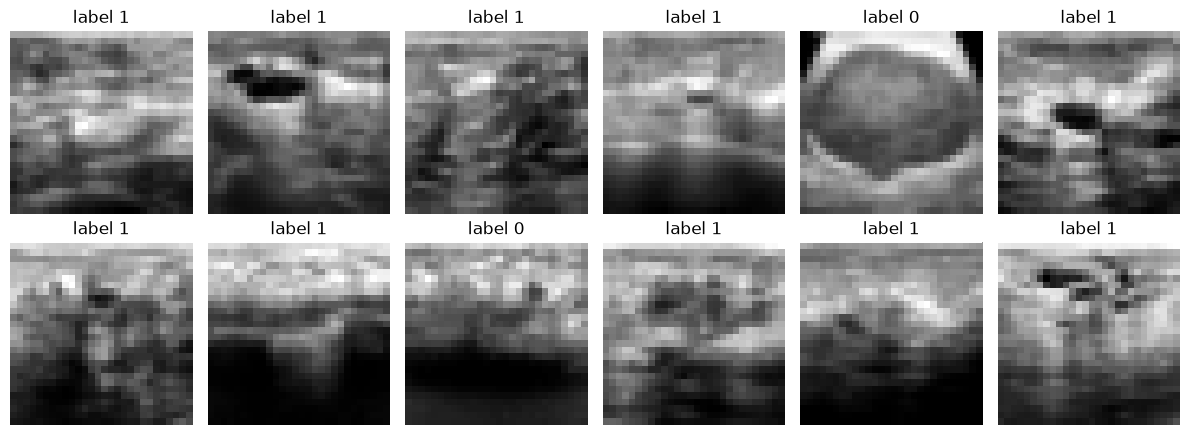

In [142]:
# Showing the first 12 training pictures with their labels.
# train_data.imgs holds the pictures as numbers (28 by 28 each), train_data.labels holds their labels.
figure, axes = pyplot.subplots(2, 6, figsize=(12, 4.5))

# axes is a grid of 2 rows and 6 columns; .flatten() turns it into one list of 12 spots.
for position, axis in enumerate(axes.flatten()):
    axis.imshow(train_data.imgs[position], cmap="gray")    # cmap="gray" draws the numbers as grayscale
    axis.set_title("label " + str(int(train_data.labels[position][0])))
    axis.axis("off")                                        # hiding the numbered axes around each picture

pyplot.tight_layout()
pyplot.show()

### **Step 6: A do-nothing baseline**

Before training, I want a score *"a baseline"* from a method that ignores the pictures completely. Without it, a model score has nothing to be compared against.

The baseline here is *always answering the most common class* from the training set. Its accuracy is the share of test pictures that belong to that class. Its **area under the receiver operating characteristic curve is 0.5**, because answering the same thing for every picture cannot rank any pictures above others at all.

In [143]:
# Collecting the labels of the training and test sets as flat lists of whole numbers.
# .ravel() flattens (number of pictures, 1) into (number of pictures,).
training_labels = train_data.labels.ravel()
test_labels = test_data.labels.ravel()

# Finding the most common class in the training set.
# numpy.bincount counts how many times 0 and 1 occur; .argmax() picks the label with the higher count.
most_common_class = int(numpy.bincount(training_labels).argmax())

# Accuracy of always answering that class on the test set: the share of test pictures with that label.
# Expected: class 1, and an accuracy equal to the share of label 1 in the test split (see the Step 2 table).
baseline_accuracy = float((test_labels == most_common_class).mean())

print("Most common class in training:", most_common_class)
print("Accuracy of always answering that class on the test set:", round(baseline_accuracy, 3))
print("Area under the curve of that rule: 0.5 (it cannot rank pictures at all)")

Most common class in training: 1
Accuracy of always answering that class on the test set: 0.731
Area under the curve of that rule: 0.5 (it cannot rank pictures at all)


### **Step 7: The Model**

The network is small, with only 546 training pictures, a large network would simply memorize them.

- A **convolution layer** slides a small window (3 by 3 pixels) over the picture and looks for patterns, such as edges or bright and dark regions.

- *ReLU* sets negative values to zero. *MaxPool2d* keeps the strongest value in each 2 by 2 block, which halves the picture size.

- At the end, the maps are flattened into one list of numbers, and the last layers turn it into **one score per picture**. A high score means the network leans towards label 1 (normal, benign), a low score towards label 0 (malignant).

In [144]:
# Defining the network. 
# nn.Module is PyTorch's base class for networks.
class SmallConvolutionalNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.convolution_layers = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),    # 1 picture -> 16 pattern maps, size stays 28 by 28
            nn.ReLU(),
            nn.MaxPool2d(2),                               # picture size 28 -> 14
            nn.Conv2d(16, 32, kernel_size=3, padding=1),   # 16 maps -> 32 maps
            nn.ReLU(),
            nn.MaxPool2d(2),                               # picture size 14 -> 7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                                  # 32 maps of 7 by 7 -> one list of 1568 numbers
            nn.Linear(32 * 7 * 7, 64),                     # 1568 numbers -> 64 numbers
            nn.ReLU(),
            nn.Linear(64, 1),                              # 64 numbers -> 1 score per picture
        )

    def forward(self, pictures):
        # The path a batch of pictures takes through the network.
        return self.classifier(self.convolution_layers(pictures))


# Checking the shapes with the batch from Step 4.
# Expected: (64, 1), meaning one score for each of the 64 pictures.
example_model = SmallConvolutionalNetwork()
print("Output shape:", example_model(images).shape)

# Counting the numbers the network can learn. Expected: 105281.
print("Learnable numbers:", sum(parameter.numel() for parameter in example_model.parameters()))

Output shape: torch.Size([64, 1])
Learnable numbers: 105281


### **Step 8: Model Training**

Training repeats the same five actions on small groups of pictures (batches). One full pass through all training pictures is called an **epoch**:

1. Clearing the old corrections.
2. Letting the network guess the scores of a batch.
3. Measuring how wrong the guesses are (the **loss**).
4. Working out in which direction each learnable number should move.
5. Moving every number a little in that direction.

After each epoch, the model is tested on the **validation pictures**, never on the test pictures. The epoch with the best validation score is the one that is kept, because later epochs can start to memorize the training pictures (**overfitting**).

The score used here is the **area under the receiver operating characteristic curve**, with label 1 as the positive class, as in the MedMNIST paper. *Seed* fixes the random choices (starting numbers and picture order), so that a run can be repeated.

In [145]:
# HELPER FUNCTION
# turning the scores of the network into probabilities for a whole loader.
def predict_probabilities(model, loader):
    # Returns the true labels and the model's probability of label 1 for every picture.
    model.eval()                                      # switching the model to evaluation mode
    collected_labels = []
    collected_probabilities = []
    with torch.no_grad():                             # no corrections are needed here, so nothing is tracked
        for batch_images, batch_labels in loader:
            scores = model(batch_images)              # shape (batch, 1)
            probabilities = torch.sigmoid(scores).squeeze(1)    # sigmoid turns any score into a probability between 0 and 1
            collected_probabilities.append(probabilities)
            collected_labels.append(batch_labels.squeeze(1))    # (batch, 1) -> (batch,)
    return torch.cat(collected_labels).numpy(), torch.cat(collected_probabilities).numpy()

In [146]:
# TRAINING FUNCTION 
# trains one network from scratch and returns the best version with its history.
def train_model(seed, number_of_epochs=30, learning_rate=0.001):
    # Fixing the random numbers, so that the run can be repeated.
    torch.manual_seed(seed)
    numpy.random.seed(seed)
    generator = torch.Generator().manual_seed(seed)    # makes the shuffling of the pictures repeatable
    seeded_train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, generator=generator)

    model = SmallConvolutionalNetwork()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)    # Adam decides how far to move each number
    loss_function = nn.BCEWithLogitsLoss()    # the loss for a two-class task with one score per picture

    best_validation_score = -1.0
    best_weights = copy.deepcopy(model.state_dict())    # a saved copy of the best version so far
    history = []

    for epoch in range(1, number_of_epochs + 1):
        model.train()                                    # switching the model to training mode
        loss_sum = 0.0
        for batch_images, batch_labels in seeded_train_loader:
            batch_labels = batch_labels.float()          # the loss expects decimal numbers; shape (batch, 1) matches the scores
            optimizer.zero_grad()                        # (1) clearing the old corrections
            scores = model(batch_images)                 # (2) guessing
            loss = loss_function(scores, batch_labels)   # (3) measuring how wrong
            loss.backward()                              # (4) working out the direction to move
            optimizer.step()                             # (5) moving a little
            loss_sum += loss.item() * len(batch_labels)
        train_loss = loss_sum / len(train_dataset)

        # Testing on the validation pictures after every epoch.
        validation_true, validation_probabilities = predict_probabilities(model, validation_loader)
        validation_loss = sklearn.metrics.log_loss(validation_true, validation_probabilities, labels=[0, 1])
        validation_score = sklearn.metrics.roc_auc_score(validation_true, validation_probabilities)
        history.append({"epoch": epoch, "train_loss": train_loss,
                        "validation_loss": validation_loss, "validation_area_under_curve": validation_score})

        # Remembering the best version so far.
        if validation_score > best_validation_score:
            best_validation_score = validation_score
            best_weights = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_weights)    # going back to the best version
    return model, pandas.DataFrame(history)

A network starts with random numbers, and the loader shuffles the pictures in a random order. Adding a seed fixes both, so if you run the cell again you get the same result. Without it, every run would differ slightly and we couldn’t debug anything.

0 it is an arbitrary choice (Love 42, will add it later), but since this is the experimental run,  0 is just the first one, and Step 10 later repeats the run with seeds 0, 1 and 42.

In [147]:
# One first run with seed 0. This takes a short while.
model_seed0, history_seed0 = train_model(seed=0)

# Showing the last 5 epochs of the history.
print(history_seed0.tail().round(3).to_string())

    epoch  train_loss  validation_loss  validation_area_under_curve
25     26       0.448            0.472                        0.824
26     27       0.444            0.471                        0.826
27     28       0.430            0.462                        0.822
28     29       0.422            0.457                        0.832
29     30       0.416            0.454                        0.830


**Checking learning curves**:

- Training loss going down is expected.
- If the validation loss turns upward while the training loss keeps going down, the model has started to **overfit**. That is normal with 546 training pictures, and it is the reason for choosing the best epoch rather than the last one.
- A jagged validation curve is expected, because the validation split has only 78 pictures.

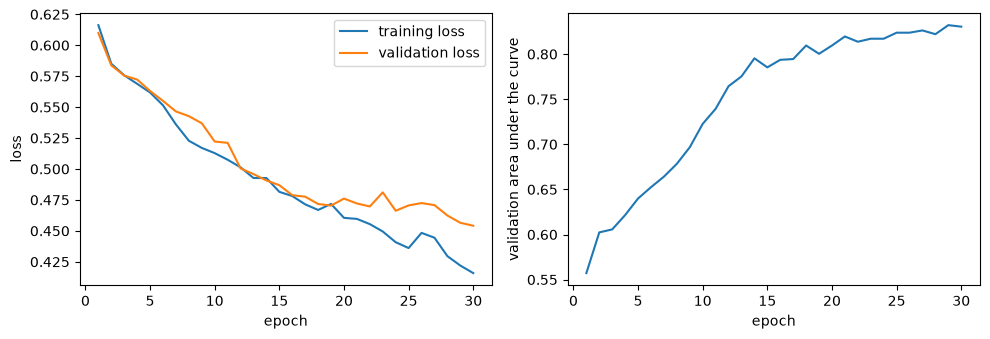

In [148]:
# Drawing two plots next to each other: the losses, and the validation score per epoch.
figure, axes = pyplot.subplots(1, 2, figsize=(10, 3.5))

axes[0].plot(history_seed0["epoch"], history_seed0["train_loss"], label="training loss")
axes[0].plot(history_seed0["epoch"], history_seed0["validation_loss"], label="validation loss")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].legend()

axes[1].plot(history_seed0["epoch"], history_seed0["validation_area_under_curve"])
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("validation area under the curve")

pyplot.tight_layout()
pyplot.show()

### **Step 9: Model Testing**

The test pictures are used **once**, only now, after the model has been chosen. Three things are checked:

- The **area under the curve** on the test pictures.
- The **accuracy**, next to the baseline from Step 6.
- The **confusion matrix**, which counts right and wrong answers per class: rows are the true label, columns the predicted label. The first row holds the malignant pictures (label 0), so its first number shows how many of them were caught.

A picture is predicted as label 1 when its probability is 0.5 or higher.

In [149]:
# HELPER FUNCTION
# calculating ALL test metrics from the true labels and the probabilities.
# Label 0 (malignant) is the class we most want to catch, so the class-based metrics are written from its point of view.
def calculate_test_metrics(true_values, probabilities, cutoff=0.5):
    predictions = (probabilities >= cutoff).astype(int)

    # Rows = true label, columns = predicted label.
    matrix = sklearn.metrics.confusion_matrix(true_values, predictions)
    malignant_caught, malignant_missed = matrix[0, 0], matrix[0, 1]
    false_alarms, normal_caught = matrix[1, 0], matrix[1, 1]

    sensitivity = malignant_caught / (malignant_caught + malignant_missed)    # share of malignant pictures that were found
    specificity = normal_caught / (normal_caught + false_alarms)              # share of normal or benign pictures that were found
    precision = malignant_caught / (malignant_caught + false_alarms)          # share of "malignant" answers that were right

    metrics = {
        "test_area_under_curve": sklearn.metrics.roc_auc_score(true_values, probabilities),
        "test_accuracy": sklearn.metrics.accuracy_score(true_values, predictions),
        "balanced_accuracy": (sensitivity + specificity) / 2,                 # average of the two shares, so the small class counts equally
        "sensitivity": sensitivity,
        "specificity": specificity,
        "precision": precision,
        "f1_malignant": 2 * precision * sensitivity / (precision + sensitivity),
        "matthews_correlation": sklearn.metrics.matthews_corrcoef(true_values, predictions),
    }
    return metrics, matrix

In [150]:
# Getting the true labels and the probabilities for the test pictures.
test_true, test_probabilities = predict_probabilities(model_seed0, test_loader)

# Turning probabilities into answers: 1 if the probability is 0.5 or higher, otherwise 0.
test_predictions = (test_probabilities >= 0.5).astype(int)

# All metrics come from the helper above.
test_metrics, test_matrix = calculate_test_metrics(test_true, test_probabilities)
test_area_under_curve = test_metrics["test_area_under_curve"]    # also used by the curve plot below

print("Test metrics:")
for metric_name, metric_value in test_metrics.items():
    print(metric_name.ljust(21), ":", round(metric_value, 3))
print("baseline accuracy".ljust(21), ":", round(baseline_accuracy, 3), "(Step 6)")
print()

# Rows = true label (0 and 1), columns = predicted label (0 and 1).
print("Confusion matrix:")
print(test_matrix)

Test metrics:
test_area_under_curve : 0.845
test_accuracy         : 0.827
balanced_accuracy     : 0.701
sensitivity           : 0.429
specificity           : 0.974
precision             : 0.857
f1_malignant          : 0.571
matthews_correlation  : 0.523
baseline accuracy     : 0.731 (Step 6)

Confusion matrix:
[[ 18  24]
 [  3 111]]


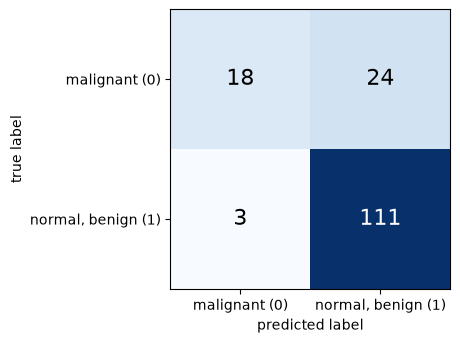

In [151]:
# Drawing the confusion matrix as a coloured grid, with the counts written in the squares.
matrix = sklearn.metrics.confusion_matrix(test_true, test_predictions)
class_names = ["malignant (0)", "normal, benign (1)"]

figure, axis = pyplot.subplots(figsize=(4.5, 4))
axis.imshow(matrix, cmap="Blues")
axis.set_xticks([0, 1])
axis.set_xticklabels(class_names)
axis.set_yticks([0, 1])
axis.set_yticklabels(class_names)
axis.set_xlabel("predicted label")
axis.set_ylabel("true label")

for row in range(2):
    for column in range(2):
        axis.text(column, row, matrix[row, column], ha="center", va="center", fontsize=16,
                  color="white" if matrix[row, column] > matrix.max() / 2 else "black")

pyplot.tight_layout()
pyplot.show()

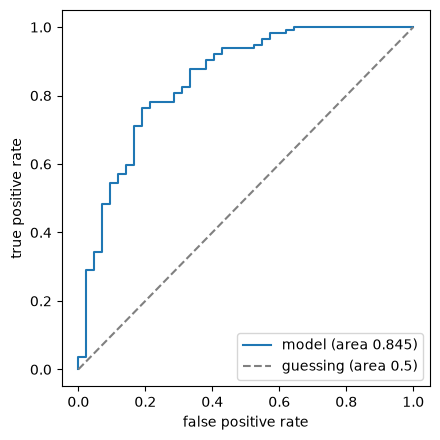

In [152]:
# Drawing the receiver operating characteristic curve.
# roc_curve returns, for many cut-off values, how often label 1 is wrongly accepted (false positive rate)
# and how often it is rightly accepted (true positive rate). The first two returned lists are used.
false_positive_rate, true_positive_rate, _ = sklearn.metrics.roc_curve(test_true, test_probabilities)

pyplot.figure(figsize=(4.5, 4.5))
pyplot.plot(false_positive_rate, true_positive_rate, label="model (area " + str(round(test_area_under_curve, 3)) + ")")
pyplot.plot([0, 1], [0, 1], linestyle="--", color="grey", label="guessing (area 0.5)")    # the diagonal line = guessing
pyplot.xlabel("false positive rate")
pyplot.ylabel("true positive rate")
pyplot.legend()
pyplot.tight_layout()
pyplot.show()

### **Step 10: Repetition & Reproducibility**
One run can be lucky or unlucky, because the starting numbers and the picture order are random. So the whole training is repeated with **three seeds** (0, 1 and 42), and the test results are reported as a **mean and a spread**.

The test split has only 156 pictures, so every single picture moves the score noticeably. Some spread between seeds is expected and is not a failure.

 seed  test_area_under_curve  test_accuracy  balanced_accuracy  sensitivity  specificity  precision  f1_malignant  matthews_correlation
    0                  0.845          0.827              0.701        0.429        0.974      0.857         0.571                 0.523
    1                  0.850          0.827              0.724        0.500        0.947      0.778         0.609                 0.525
   42                  0.840          0.801              0.676        0.405        0.947      0.739         0.523                 0.441

      test_area_under_curve  test_accuracy  balanced_accuracy  sensitivity  specificity  precision  f1_malignant  matthews_correlation
mean                  0.845          0.818              0.700        0.444        0.956      0.791         0.568                 0.496
std                   0.005          0.015              0.024        0.050        0.015      0.060         0.043                 0.048


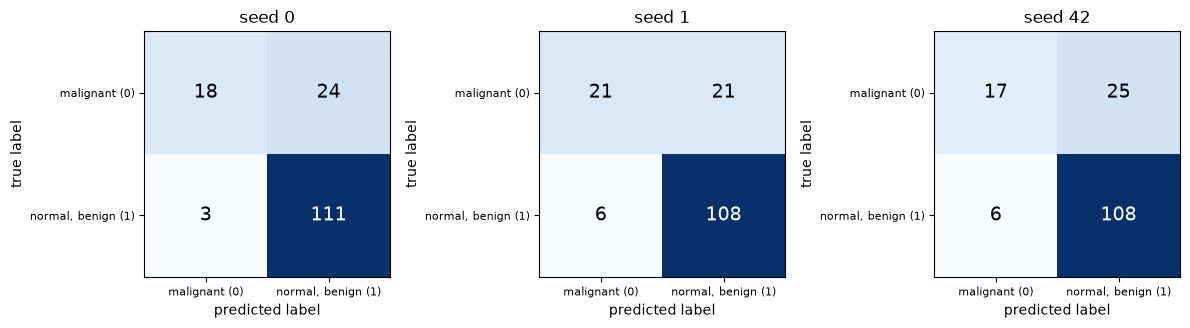

In [153]:
# Training and testing with seeds 0, 1 and 42. This takes a few minutes.
seeds = [0, 1, 42]
result_rows = []
confusion_matrices = {}
for seed in seeds:
    trained_model, _ = train_model(seed=seed)
    true_values, probabilities = predict_probabilities(trained_model, test_loader)
    metrics, matrix = calculate_test_metrics(true_values, probabilities)
    confusion_matrices[seed] = matrix
    result_rows.append({"seed": seed, **metrics})

# One row per seed, then the mean and the standard deviation (the typical spread) of every column.
results_table = pandas.DataFrame(result_rows)
print(results_table.round(3).to_string(index=False))
print()
print(results_table.drop(columns="seed").agg(["mean", "std"]).round(3).to_string())

# One confusion matrix per seed, next to each other.
figure, axes = pyplot.subplots(1, len(seeds), figsize=(4 * len(seeds), 3.8))
class_names = ["malignant (0)", "normal, benign (1)"]
for axis, seed in zip(axes, seeds):
    matrix = confusion_matrices[seed]
    axis.imshow(matrix, cmap="Blues")
    axis.set_title("seed " + str(seed))
    axis.set_xticks([0, 1])
    axis.set_xticklabels(class_names, fontsize=8)
    axis.set_yticks([0, 1])
    axis.set_yticklabels(class_names, fontsize=8)
    axis.set_xlabel("predicted label")
    axis.set_ylabel("true label")
    for row in range(2):
        for column in range(2):
            axis.text(column, row, matrix[row, column], ha="center", va="center", fontsize=14,
                      color="white" if matrix[row, column] > matrix.max() / 2 else "black")
pyplot.tight_layout()
pyplot.show()

### **Step 11: Conclusions**